In [3]:
import pandas as pd
import numpy as np
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import levene
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

# Load the dataset
df = pd.read_csv("global_power_plant_database.csv")

# Display all column names
print("Columns:")
print(df.columns)

# Initial exploration
print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Standardise column names
# Remove leading/trailing spaces and replace spaces with underscores
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Convert relevant columns to numeric data types. Invalid values will be converted to NaN
numeric_columns = ['capacity_mw', 'commissioning_year']

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].astype(np.float64)

# Check missing values after conversion
print("\nMissing values per column:")
print(df.isnull().sum())

# Calculate percentage of missing values
missing_pct = (df.isnull().sum() / len(df)) * 100

print("\nPercentage missing:")
print(missing_pct.sort_values(ascending=False))

# Drop columns with more than 50% missing values
threshold = 0.5

cols_to_drop = missing_pct[missing_pct > threshold * 100].index

print("\nColumns dropped:")
print(list(cols_to_drop))

df = df.drop(columns=cols_to_drop)

# Select all numeric columns
numeric_cols = df.select_dtypes(include=['number']).columns

# Fill missing numeric values with the median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Select all categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# Fill missing categorical values with the mode
for col in categorical_cols:

    mode_value = df[col].mode()

    if not mode_value.empty:
        df[col] = df[col].fillna(mode_value[0])
    else:
        df[col] = df[col].fillna("Unknown")

# Verify that missing values have been handled
print("\nRemaining missing values:")
print(df.isnull().sum())

# Verify final data types
print("\nFinal Data Types:")
print(df.dtypes)

# Display final dataset shape
print("\nFinal Dataset Shape:", df.shape)

C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\4055660850.py:12: DtypeWarning: Columns (10: other_fuel3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("global_power_plant_database.csv")


Columns:
Index(['country', 'country_long', 'name', 'gppd_idnr', 'capacity_mw',
       'latitude', 'longitude', 'primary_fuel', 'other_fuel1', 'other_fuel2',
       'other_fuel3', 'commissioning_year', 'owner', 'source', 'url',
       'geolocation_source', 'wepp_id', 'year_of_capacity_data',
       'generation_gwh_2013', 'generation_gwh_2014', 'generation_gwh_2015',
       'generation_gwh_2016', 'generation_gwh_2017', 'generation_gwh_2018',
       'generation_gwh_2019', 'generation_data_source',
       'estimated_generation_gwh_2013', 'estimated_generation_gwh_2014',
       'estimated_generation_gwh_2015', 'estimated_generation_gwh_2016',
       'estimated_generation_gwh_2017', 'estimated_generation_note_2013',
       'estimated_generation_note_2014', 'estimated_generation_note_2015',
       'estimated_generation_note_2016', 'estimated_generation_note_2017'],
      dtype='str')

Dataset Shape: (34936, 36)

Missing Values:
country                               0
country_long             

C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\4055660850.py:73: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns



Remaining missing values:
country                           0
country_long                      0
name                              0
gppd_idnr                         0
capacity_mw                       0
latitude                          0
longitude                         0
primary_fuel                      0
owner                             0
source                            0
url                               0
geolocation_source                0
estimated_generation_gwh_2016     0
estimated_generation_gwh_2017     0
estimated_generation_note_2013    0
estimated_generation_note_2014    0
estimated_generation_note_2015    0
estimated_generation_note_2016    0
estimated_generation_note_2017    0
dtype: int64

Final Data Types:
country                               str
country_long                          str
name                                  str
gppd_idnr                             str
capacity_mw                       float64
latitude                          float64
longi

In [4]:
# Exploratory data analysis

# Select only columns with numeric data types
numeric_cols = df.select_dtypes(include=['number'])

# Create a DataFrame containing summary statistics
summary_stats = pd.DataFrame({

    # Calculate the average value for each numerical column
    'Mean': numeric_cols.mean(),

    # Calculate the middle value for each numerical column
    'Median': numeric_cols.median(),

    # Calculate the standard deviation to measure data spread
    'Standard Deviation': numeric_cols.std()
})

# Display the resulting statistics table
print("\nSummary Statistics:")
print(summary_stats)

# Count power plants by country
country_distribution = df['country_long'].value_counts()

print("\nDistribution of Power Plants by Country:")
print(country_distribution)

# Count power plants by country
country_distribution = df['country_long'].value_counts()

print("\nDistribution of Power Plants by Country:")
print(country_distribution)


Summary Statistics:
                                     Mean    Median  Standard Deviation
capacity_mw                    163.355148  16.74500          489.636072
latitude                        32.816637  39.72775           22.638603
longitude                       -6.972803  -2.12710           78.405850
estimated_generation_gwh_2016  132.232824  27.55500          899.269378
estimated_generation_gwh_2017  681.505825  37.59000         2424.229996

Distribution of Power Plants by Country:
country_long
United States of America    9833
China                       4235
United Kingdom              2751
Brazil                      2360
France                      2155
                            ... 
Lesotho                        1
Palestine                      1
Saint Lucia                    1
Suriname                       1
Western Sahara                 1
Name: count, Length: 167, dtype: int64

Distribution of Power Plants by Country:
country_long
United States of America    9833
Ch

In [5]:
# Distribution of power plants by country

# Count the number of power plants in each country
country_distribution = df['country_long'].value_counts()

# Display the results
print("\nPower Plants by Country:")
print(country_distribution)

# Display the top 10 countries with the most power plants
print("\nTop 10 Countries:")
print(country_distribution.head(10))

# Count the number of power plants for each primary fuel source
fuel_distribution = df['primary_fuel'].value_counts()

# Display the results
print("\nPower Plants by Fuel Type:")
print(fuel_distribution)

# Display the most common fuel types
print("\nMost Common Fuel Types:")
print(fuel_distribution.head(10))

# Create a table showing the distribution of fuel types within each country
country_fuel_table = pd.crosstab(
    df['country_long'],
    df['primary_fuel']
)

print("\nCountry vs Fuel Type Distribution:")
print(country_fuel_table)

# Calculate statistics for capacity grouped by fuel type
fuel_capacity_stats = df.groupby('primary_fuel')['capacity_mw'].agg([
    'count',
    'mean',
    'median',
    'std',
    'min',
    'max'
])

print("\nCapacity Statistics by Fuel Type:")
print(fuel_capacity_stats)

# Calculate percentage share of each fuel type
fuel_percentage = (
    df['primary_fuel'].value_counts(normalize=True) * 100
).round(2)

print("\nFuel Type Percentage Distribution:")
print(fuel_percentage)


Power Plants by Country:
country_long
United States of America    9833
China                       4235
United Kingdom              2751
Brazil                      2360
France                      2155
                            ... 
Lesotho                        1
Palestine                      1
Saint Lucia                    1
Suriname                       1
Western Sahara                 1
Name: count, Length: 167, dtype: int64

Top 10 Countries:
country_long
United States of America    9833
China                       4235
United Kingdom              2751
Brazil                      2360
France                      2155
India                       1589
Germany                     1309
Canada                      1159
Spain                        829
Russia                       545
Name: count, dtype: int64

Power Plants by Fuel Type:
primary_fuel
Solar             10665
Hydro              7156
Wind               5344
Gas                3998
Coal               2330
Oil       

In [6]:
# Statistical analysis
# Keep only relevant columns and remove missing values
df_clean = df[['primary_fuel', 'capacity_mw']].dropna()

# Create an empty list to store statistics
fuel_stats = []

# Loop through each fuel type
for fuel in df_clean['primary_fuel'].unique():

    # Get capacity values for the current fuel type
    values = df_clean[df_clean['primary_fuel'] == fuel]['capacity_mw'].values

    # Create a dictionary containing statistics
    stats = {
        'Fuel': fuel,
        'Count': len(values),
        'Mean_MW': np.mean(values),
        'Median_MW': np.median(values),
        'Std_MW': np.std(values),
        'Min_MW': np.min(values),
        'Max_MW': np.max(values)
    }

    # Add the dictionary to the list
    fuel_stats.append(stats)

# Convert the list of dictionaries into a DataFrame
stats_df = pd.DataFrame(fuel_stats)

# Sort fuels by average capacity from highest to lowest
stats_df = stats_df.sort_values('Mean_MW', ascending=False)

# Display the results
print(stats_df)

# Hypothesis testing to determine the mean power output differs significantly between different fuel types
# Select relevant columns and remove missing values
df_clean = df[['primary_fuel', 'capacity_mw']].dropna()

# Create a list to store capacity values for each fuel type
fuel_groups = []

# Loop through each fuel type
for fuel in df_clean['primary_fuel'].unique():

    # Extract capacity values for this fuel type
    values = df_clean[df_clean['primary_fuel'] == fuel]['capacity_mw'].values

    # Add values to the list of groups
    fuel_groups.append(values)

# Perform the one-way ANOVA test
f_statistic, p_value = f_oneway(*fuel_groups)

# Display the results
print("F-statistic:", f_statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("Mean power output differs significantly between fuel types.")
else:
    print("Fail to reject the null hypothesis.")
    print("No significant difference detected.")

              Fuel  Count      Mean_MW   Median_MW       Std_MW  Min_MW  \
6          Nuclear    195  2091.855179  1888.00000  1300.162646    20.0   
7             Coal   2330   843.579828   600.00000   887.996568     1.2   
2              Gas   3998   373.449375   147.50000   560.863990     1.0   
11         Petcoke     12   202.048125    65.48875   456.679766     4.7   
0            Hydro   7156   147.171551    20.00000   549.770911     1.0   
4              Oil   2320   112.878754     9.00000   391.924545     1.0   
14    Cogeneration     41    98.731707    31.90000   279.950473     1.6   
3            Other     43    84.020000    40.00000   144.185002     4.5   
12      Geothermal    189    67.130952    30.00000   114.337205     1.0   
10  Wave and Tidal     10    55.220000     5.00000    96.235106     1.0   
5             Wind   5344    49.224126    27.00000   106.128423     1.0   
9          Biomass   1430    23.972938     9.45000    39.448004     1.0   
1            Solar  10665

In [7]:
# Test to determine which fuel types differ

# Perform Tukey's test
tukey = pairwise_tukeyhsd(
    endog=df_clean['capacity_mw'],
    groups=df_clean['primary_fuel'],
    alpha=0.05
)

# Show results
print(tukey)

# calculate descriptive statistics first
# Group by fuel type
grouped = df_clean.groupby('primary_fuel')['capacity_mw']

# Calculate descriptive statistics
summary = grouped.agg([
    'count',
    'mean',
    'median',
    'std',
    'min',
    'max'
])

print(summary)

# Test for equal variance

# Create list of groups
fuel_groups = [
    df_clean[df_clean['primary_fuel'] == fuel]['capacity_mw'].values
    for fuel in df_clean['primary_fuel'].unique()
]

# Levene's test
stat, p = levene(*fuel_groups)

print("Levene p-value:", p)

# Keep only required columns and remove missing values
df_clean = df[['primary_fuel', 'capacity_mw']].dropna()

# Create a list to hold data for each fuel type
fuel_groups = []

# Loop through each fuel type
for fuel in df_clean['primary_fuel'].unique():

    # Extract capacity values for this fuel type
    values = df_clean[df_clean['primary_fuel'] == fuel]['capacity_mw']

    # Add to list
    fuel_groups.append(values)

# Run ANOVA
f_statistic, p_value = f_oneway(*fuel_groups)

# Display results
print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the result
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("Mean power output differs significantly between fuel types.")
else:
    print("Fail to reject the null hypothesis.")
    print("No significant difference between fuel types.")

fuels = df_clean['primary_fuel'].unique()

for i in range(len(fuels)):
    for j in range(i + 1, len(fuels)):

        group1 = df_clean[df_clean['primary_fuel'] == fuels[i]]['capacity_mw']
        group2 = df_clean[df_clean['primary_fuel'] == fuels[j]]['capacity_mw']

        stat, p = ttest_ind(group1, group2, equal_var=False)

        print(f"{fuels[i]} vs {fuels[j]}")
        print(f"P-value: {p:.5f}")

        if p < 0.05:
            print("Significant difference\n")
        else:
            print("No significant difference\n")

c:\Users\USER1\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\scipy\integrate\_quadpack_py.py:1286: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,


            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
    group1         group2      meandiff  p-adj    lower      upper    reject
----------------------------------------------------------------------------
       Biomass           Coal   819.6069    0.0   772.2455   866.9683   True
       Biomass   Cogeneration    74.7588 0.9985  -148.5588   298.0763  False
       Biomass            Gas   349.4764    0.0   306.0347   392.9182   True
       Biomass     Geothermal     43.158 0.9917   -65.9611   152.2772  False
       Biomass          Hydro   123.1986    0.0    82.3602    164.037   True
       Biomass        Nuclear  2067.8822    0.0  1960.2561  2175.5084   True
       Biomass            Oil    88.9058    0.0    41.5056    136.306   True
       Biomass          Other    60.0471 0.9998  -158.1634   278.2576  False
       Biomass        Petcoke   178.0752 0.9794  -230.6209   586.7713  False
       Biomass          Solar    -6.3159    1.0   -46.0196    33.3878  False

In [8]:
# Time series analysis

df = pd.read_csv(
    "global_power_plant_database.csv",
    low_memory=False
)

# Select generation columns
generation_cols = [
    'generation_gwh_2013',
    'generation_gwh_2014',
    'generation_gwh_2015',
    'generation_gwh_2016',
    'generation_gwh_2017',
    'generation_gwh_2018',
    'generation_gwh_2019'
]

# Calculate the mean generation for each year
yearly_means = []

for col in generation_cols:

    # Calculate average generation for that year
    mean_value = np.nanmean(df[col])

    # Store result
    yearly_means.append(mean_value)

# Display results
for year, mean in zip(range(2013, 2020), yearly_means):
    print(f"{year}: {mean:.2f} GWh")

# Calculate year on year growth

# Convert means to NumPy array
yearly_means = np.array(yearly_means)

# Calculate annual growth rates
growth_rates = np.diff(yearly_means) / yearly_means[:-1] * 100

# Display results
for year, growth in zip(range(2014, 2020), growth_rates):
    print(f"{year}: {growth:.2f}%")

# Calculate the overall trend using linear regression

# Create array of years
years = np.array([2013, 2014, 2015, 2016, 2017, 2018, 2019])

# Fit a straight line
slope, intercept = np.polyfit(years, yearly_means, 1)

print("Slope:", slope)

if slope > 0:
    print("Overall generation is increasing over time.")
elif slope < 0:
    print("Overall generation is decreasing over time.")
else:
    print("No overall trend detected.")

# Loop through each fuel type
for fuel in df['primary_fuel'].dropna().unique():

    # Select rows for the fuel type
    fuel_data = df[df['primary_fuel'] == fuel]

    # Calculate average generation for each year
    means = np.array([
        np.nanmean(fuel_data['generation_gwh_2013']),
        np.nanmean(fuel_data['generation_gwh_2014']),
        np.nanmean(fuel_data['generation_gwh_2015']),
        np.nanmean(fuel_data['generation_gwh_2016']),
        np.nanmean(fuel_data['generation_gwh_2017']),
        np.nanmean(fuel_data['generation_gwh_2018']),
        np.nanmean(fuel_data['generation_gwh_2019'])
    ])

    # Calculate trend line slope
    slope, intercept = np.polyfit(years, means, 1)

    print(f"\nFuel Type: {fuel}")
    print(f"Trend Slope: {slope:.2f} GWh/year")

    if slope > 0:
        print("Increasing trend")
    else:
        print("Decreasing trend")

for col in generation_cols:

    print(
        col,
        np.nanstd(df[col])
    )

years = np.array([2013, 2014, 2015, 2016, 2017, 2018, 2019])

fuel_trends = []

for fuel in df['primary_fuel'].dropna().unique():

    fuel_data = df[df['primary_fuel'] == fuel]

    means = np.array([
        np.nanmean(fuel_data['generation_gwh_2013']),
        np.nanmean(fuel_data['generation_gwh_2014']),
        np.nanmean(fuel_data['generation_gwh_2015']),
        np.nanmean(fuel_data['generation_gwh_2016']),
        np.nanmean(fuel_data['generation_gwh_2017']),
        np.nanmean(fuel_data['generation_gwh_2018']),
        np.nanmean(fuel_data['generation_gwh_2019'])
    ])

    slope, _ = np.polyfit(years, means, 1)

    fuel_trends.append([fuel, slope])

# Sort by growth rate
fuel_trends.sort(key=lambda x: x[1], reverse=True)

print("Fastest-growing fuel types:")
for fuel, slope in fuel_trends:
    print(f"{fuel}: {slope:.2f} GWh/year")

2013: 592.70 GWh
2014: 656.86 GWh
2015: 762.37 GWh
2016: 693.15 GWh
2017: 661.83 GWh
2018: 517.32 GWh
2019: 423.92 GWh
2014: 10.83%
2015: 16.06%
2016: -9.08%
2017: -4.52%
2018: -21.84%
2019: -18.05%
Slope: -31.64078227251961
Overall generation is decreasing over time.

Fuel Type: Hydro
Trend Slope: -5.52 GWh/year
Decreasing trend

Fuel Type: Solar
Trend Slope: 1.33 GWh/year
Increasing trend

Fuel Type: Gas
Trend Slope: 23.21 GWh/year
Increasing trend

Fuel Type: Other
Trend Slope: -0.74 GWh/year
Decreasing trend

Fuel Type: Oil
Trend Slope: -0.84 GWh/year
Decreasing trend

Fuel Type: Wind
Trend Slope: 8.23 GWh/year
Increasing trend

Fuel Type: Nuclear
Trend Slope: 65.22 GWh/year
Increasing trend

Fuel Type: Coal
Trend Slope: -101.59 GWh/year
Decreasing trend

Fuel Type: Waste
Trend Slope: 0.00 GWh/year
Increasing trend

Fuel Type: Biomass
Trend Slope: -2.77 GWh/year
Decreasing trend

Fuel Type: Wave and Tidal
Trend Slope: nan GWh/year
Decreasing trend


C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:71: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2013']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:72: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2014']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:73: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2015']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:74: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2016']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:75: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2017']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:76: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2018']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:77: RuntimeWarning: Mean of emp


Fuel Type: Petcoke
Trend Slope: -37.01 GWh/year
Decreasing trend

Fuel Type: Geothermal
Trend Slope: -3.47 GWh/year
Decreasing trend

Fuel Type: Storage
Trend Slope: -81.54 GWh/year
Decreasing trend

Fuel Type: Cogeneration
Trend Slope: -3.59 GWh/year
Decreasing trend
generation_gwh_2013 2174.6640169859957
generation_gwh_2014 2231.3098775239723
generation_gwh_2015 2533.3054007640726
generation_gwh_2016 2404.3852747204755
generation_gwh_2017 2369.1722538148606
generation_gwh_2018 1975.2001978585074
generation_gwh_2019 1698.4185595417935
Fastest-growing fuel types:
Nuclear: 65.22 GWh/year
Gas: 23.21 GWh/year
Wind: 8.23 GWh/year
Solar: 1.33 GWh/year
Waste: 0.00 GWh/year
Other: -0.74 GWh/year
Oil: -0.84 GWh/year
Biomass: -2.77 GWh/year
Wave and Tidal: nan GWh/year
Geothermal: -3.47 GWh/year
Cogeneration: -3.59 GWh/year
Hydro: -5.52 GWh/year
Petcoke: -37.01 GWh/year
Storage: -81.54 GWh/year
Coal: -101.59 GWh/year


C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:107: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2013']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:108: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2014']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:109: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2015']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:110: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2016']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:111: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2017']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:112: RuntimeWarning: Mean of empty slice
  np.nanmean(fuel_data['generation_gwh_2018']),
C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\899772403.py:113: RuntimeWarning: Mean

primary_fuel        Biomass  Coal  Cogeneration  Gas  Geothermal  Hydro  \
commissioning_year                                                        
1896                      0     0             0    0           0      1   
1899                      0     0             0    0           0      1   
1900                      0     0             0    1           0      3   
1901                      0     0             0    0           0      2   
1902                      0     0             0    0           0      4   
...                     ...   ...           ...  ...         ...    ...   
2016                      7    84             1   43           0     45   
2017                      3    46             0   43           2     21   
2018                      3    14             0   54           2      5   
2019                      2     0             1   32           2      0   
2020                      1     0             0    6           0      0   

primary_fuel        Nucl

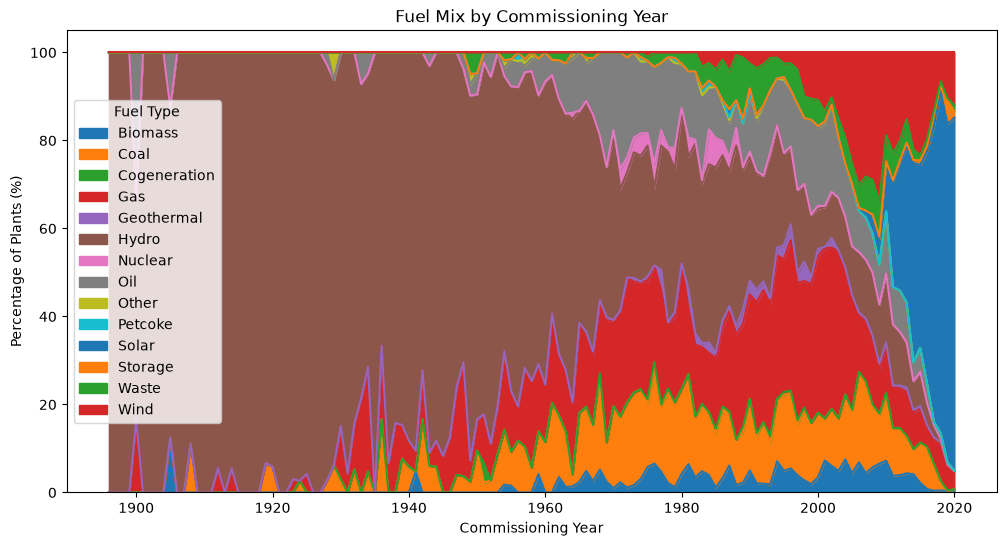

In [10]:
# Exploring how mix of fuel types of power generation has evolved over the years

# Keep only rows with a valid commissioning year
fuel_trend = df[['commissioning_year', 'primary_fuel']].dropna()

# Convert commissioning year to integer
fuel_trend['commissioning_year'] = fuel_trend['commissioning_year'].astype(int)

# Count plants by year and fuel type
fuel_by_year = pd.crosstab(
    fuel_trend['commissioning_year'],
    fuel_trend['primary_fuel']
)

print(fuel_by_year)

# Convert count to percentage
fuel_percentage = fuel_by_year.div(
    fuel_by_year.sum(axis=1),
    axis=0
) * 100

print(fuel_percentage)

# Visualise fuel mix over time

fuel_percentage.plot(
    kind='area',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Fuel Mix by Commissioning Year')
plt.xlabel('Commissioning Year')
plt.ylabel('Percentage of Plants (%)')
plt.legend(title='Fuel Type')
plt.show()

In [34]:
print(df.columns.tolist())

print(df.shape)
print(df.columns.tolist())

['country', 'country_long', 'name', 'gppd_idnr', 'capacity_mw', 'latitude', 'longitude', 'primary_fuel', 'owner', 'source', 'url', 'geolocation_source', 'estimated_generation_gwh_2016', 'estimated_generation_gwh_2017', 'estimated_generation_note_2013', 'estimated_generation_note_2014', 'estimated_generation_note_2015', 'estimated_generation_note_2016', 'estimated_generation_note_2017']
(34936, 19)
['country', 'country_long', 'name', 'gppd_idnr', 'capacity_mw', 'latitude', 'longitude', 'primary_fuel', 'owner', 'source', 'url', 'geolocation_source', 'estimated_generation_gwh_2016', 'estimated_generation_gwh_2017', 'estimated_generation_note_2013', 'estimated_generation_note_2014', 'estimated_generation_note_2015', 'estimated_generation_note_2016', 'estimated_generation_note_2017']


True
True
['country', 'country_long', 'name', 'gppd_idnr', 'capacity_mw', 'latitude', 'longitude', 'primary_fuel', 'other_fuel1', 'other_fuel2', 'other_fuel3', 'commissioning_year', 'owner', 'source', 'url', 'geolocation_source', 'wepp_id', 'year_of_capacity_data', 'generation_gwh_2013', 'generation_gwh_2014', 'generation_gwh_2015', 'generation_gwh_2016', 'generation_gwh_2017', 'generation_gwh_2018', 'generation_gwh_2019', 'generation_data_source', 'estimated_generation_gwh_2013', 'estimated_generation_gwh_2014', 'estimated_generation_gwh_2015', 'estimated_generation_gwh_2016', 'estimated_generation_gwh_2017', 'estimated_generation_note_2013', 'estimated_generation_note_2014', 'estimated_generation_note_2015', 'estimated_generation_note_2016', 'estimated_generation_note_2017']
<class 'pandas.DataFrame'>
(123, 14)
Biomass
Coal
Cogeneration
Gas
Geothermal
Hydro
Nuclear
Oil
Other
Petcoke
Solar
Storage
Waste
Wind


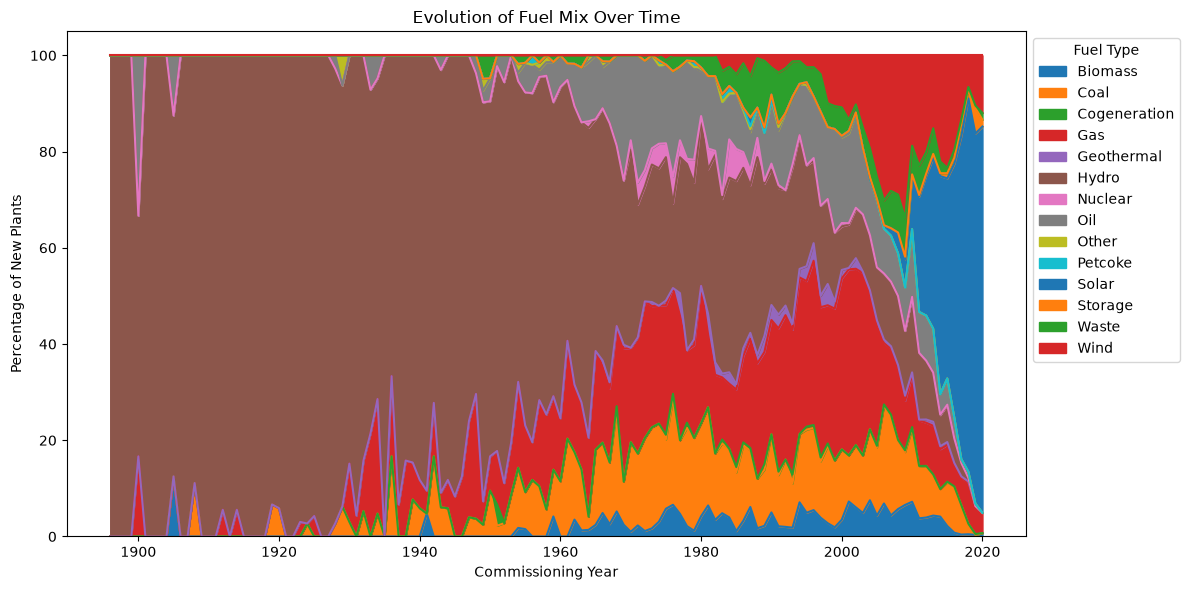

In [17]:
# Advanced visualisation

# Check that required columns exist
print("commissioning_year" in df.columns)
print("generation_gwh_2013" in df.columns)

# Display all column names
print(df.columns.tolist())

# Remove rows with missing fuel type or commissioning year
fuel_trend = df[['commissioning_year', 'primary_fuel']].dropna()

# Convert commissioning year to integer
fuel_trend['commissioning_year'] = fuel_trend['commissioning_year'].astype(int)

# Create a table of fuel counts by commissioning year
fuel_by_year = pd.crosstab(
    fuel_trend['commissioning_year'],
    fuel_trend['primary_fuel']
)

# Convert counts to percentages
fuel_percentage = fuel_by_year.div(
    fuel_by_year.sum(axis=1),
    axis=0
) * 100

# Verify structure
print(type(fuel_percentage))
print(fuel_percentage.shape)

# Display fuel types
for fuel in fuel_percentage.columns:
    print(fuel)

# Create an area chart showing how the fuel mix evolved over time
fuel_percentage.plot(
    kind='area',
    stacked=True,
    figsize=(12, 6)
)

# Add chart title and labels
plt.title('Evolution of Fuel Mix Over Time')
plt.xlabel('Commissioning Year')
plt.ylabel('Percentage of New Plants')

# Move legend outside the chart
plt.legend(
    title='Fuel Type',
    loc='upper left',
    bbox_to_anchor=(1, 1)
)

# Adjust layout to prevent clipping
plt.tight_layout()

# Display the chart
plt.show()

C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\600892886.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


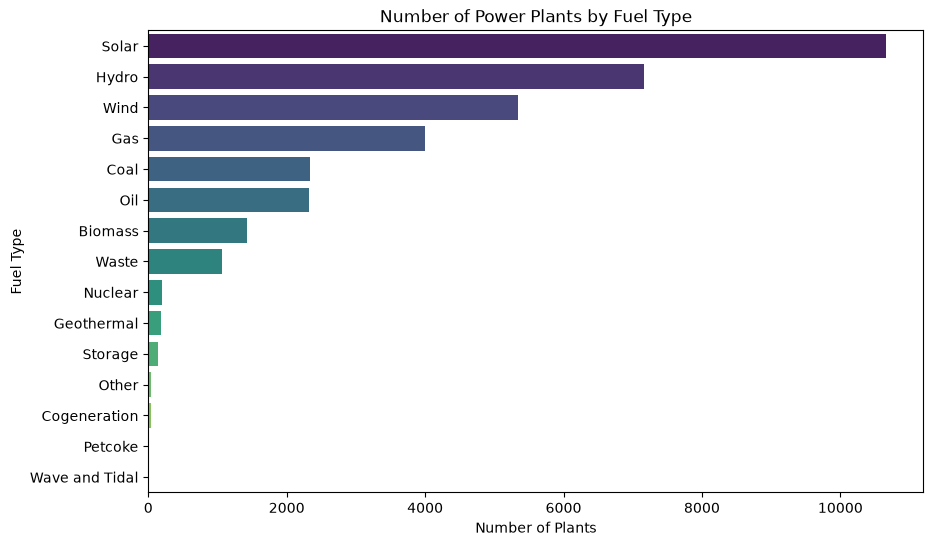

C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\600892886.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


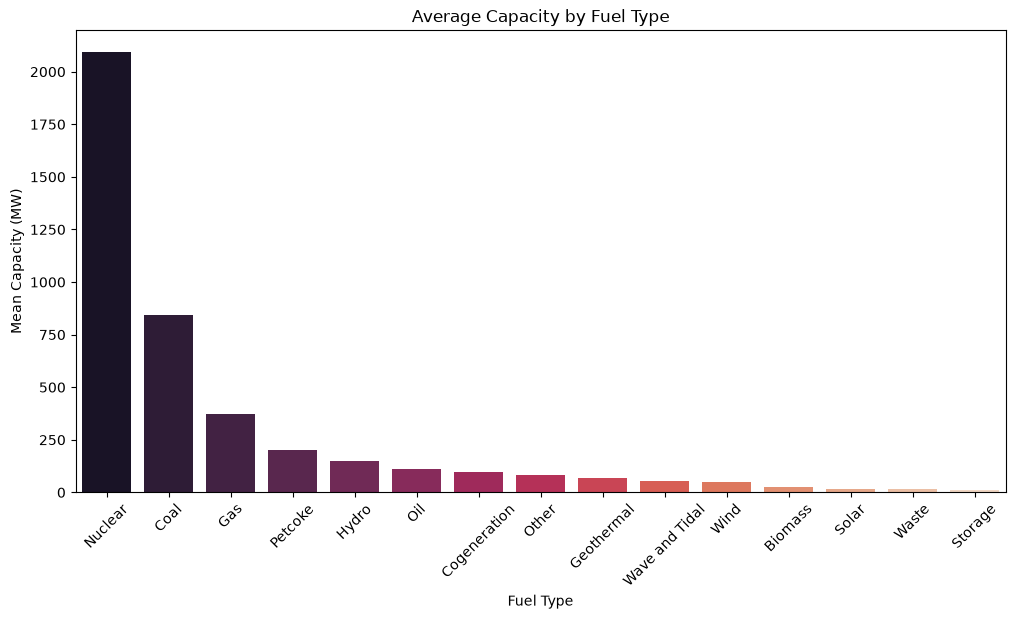

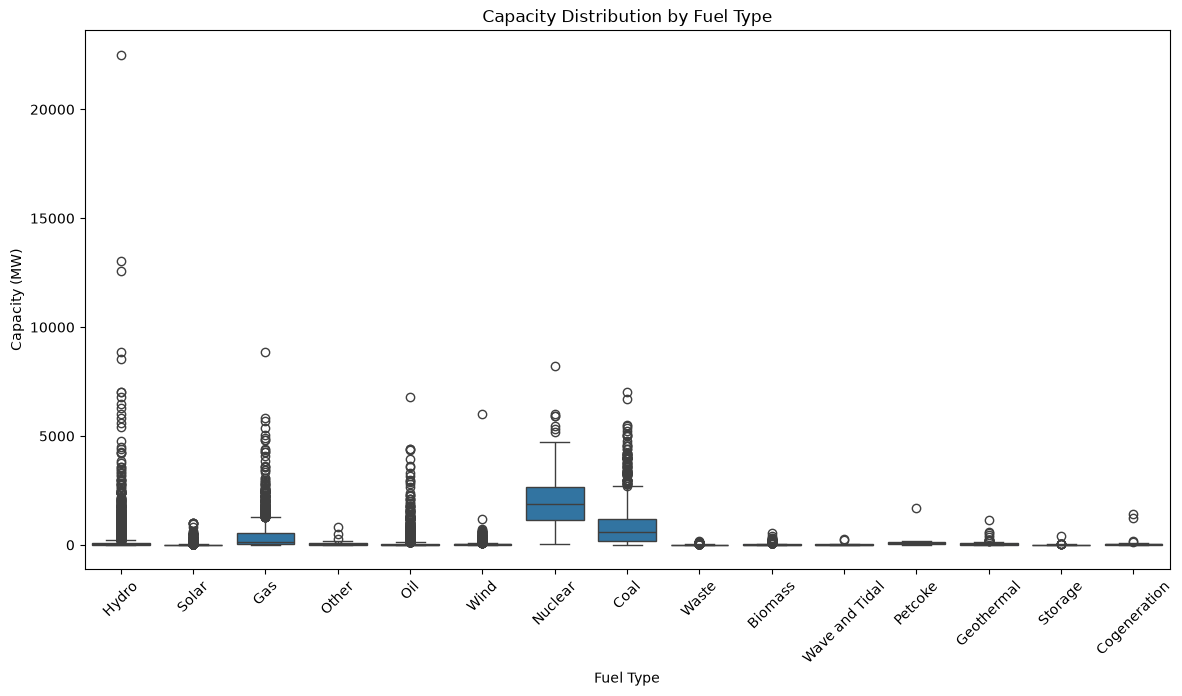

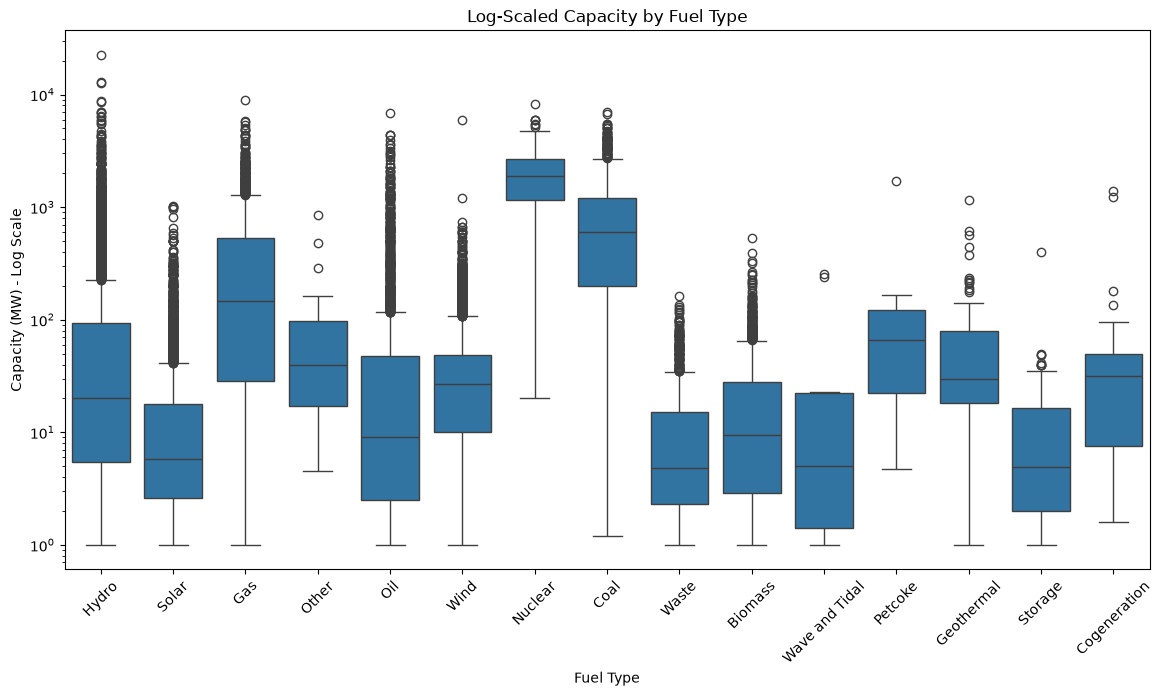

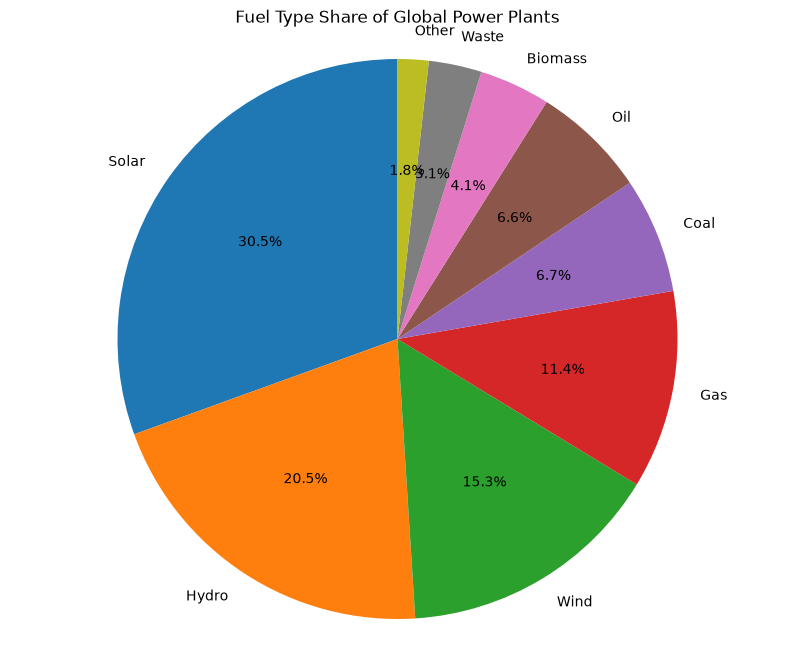

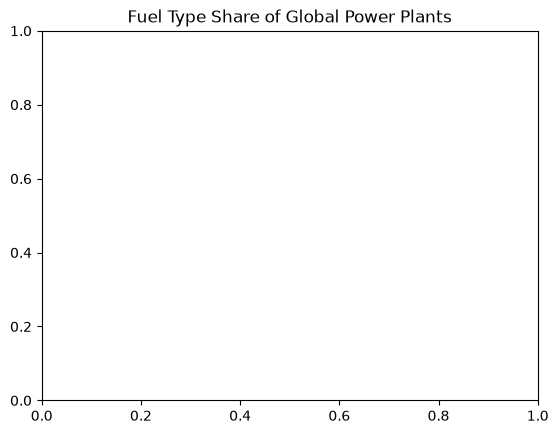

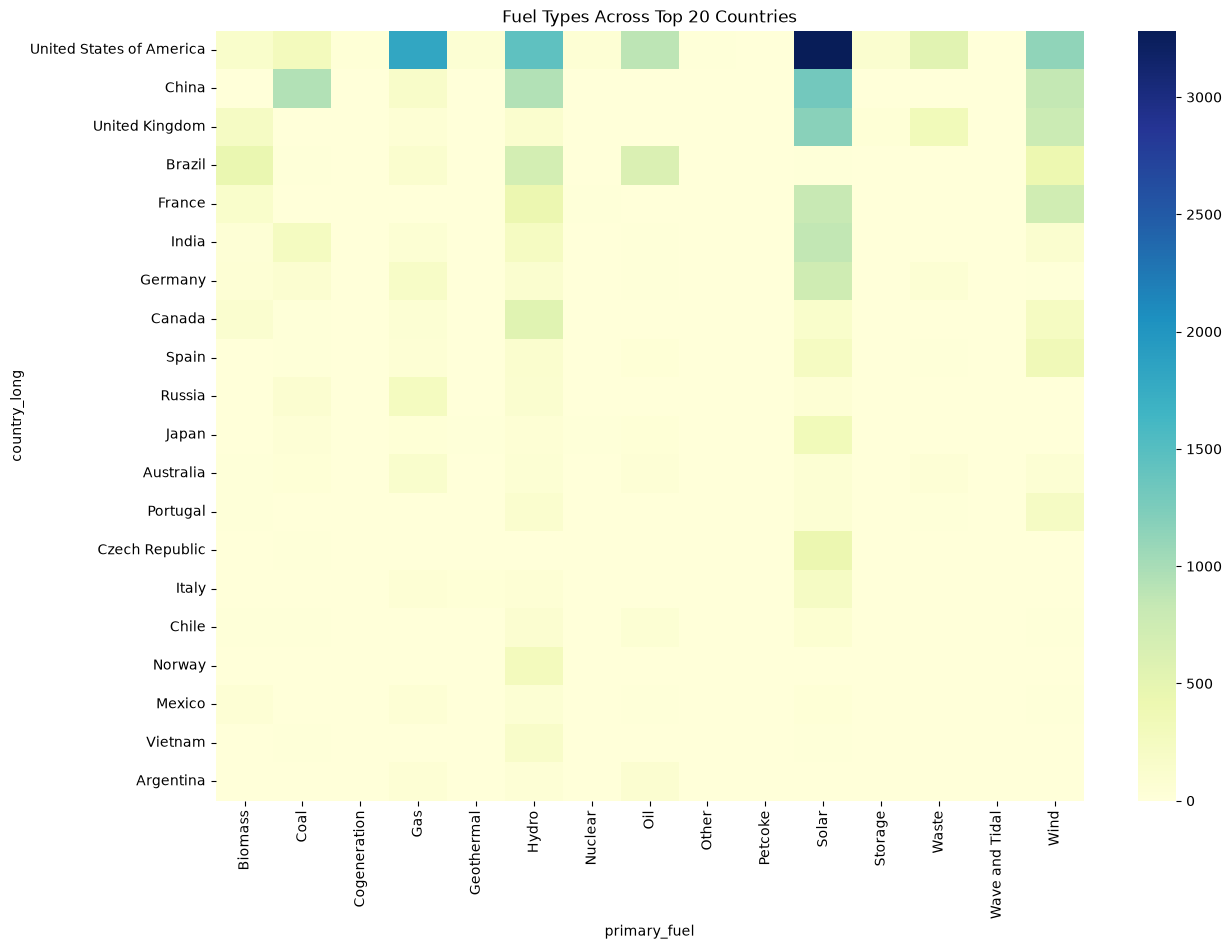

C:\Users\USER1\AppData\Local\Temp\ipykernel_25320\600892886.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


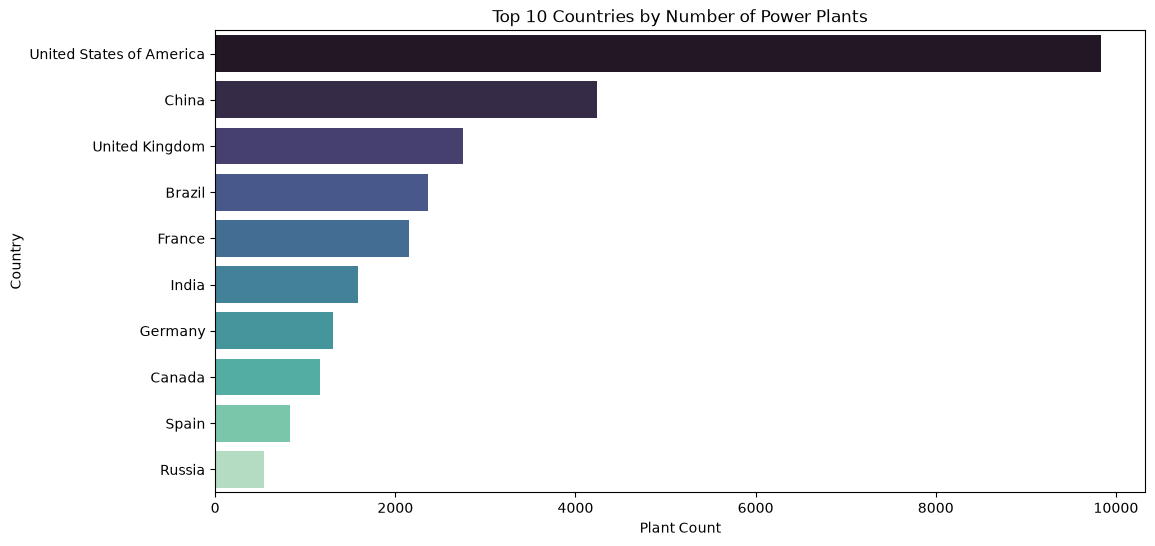

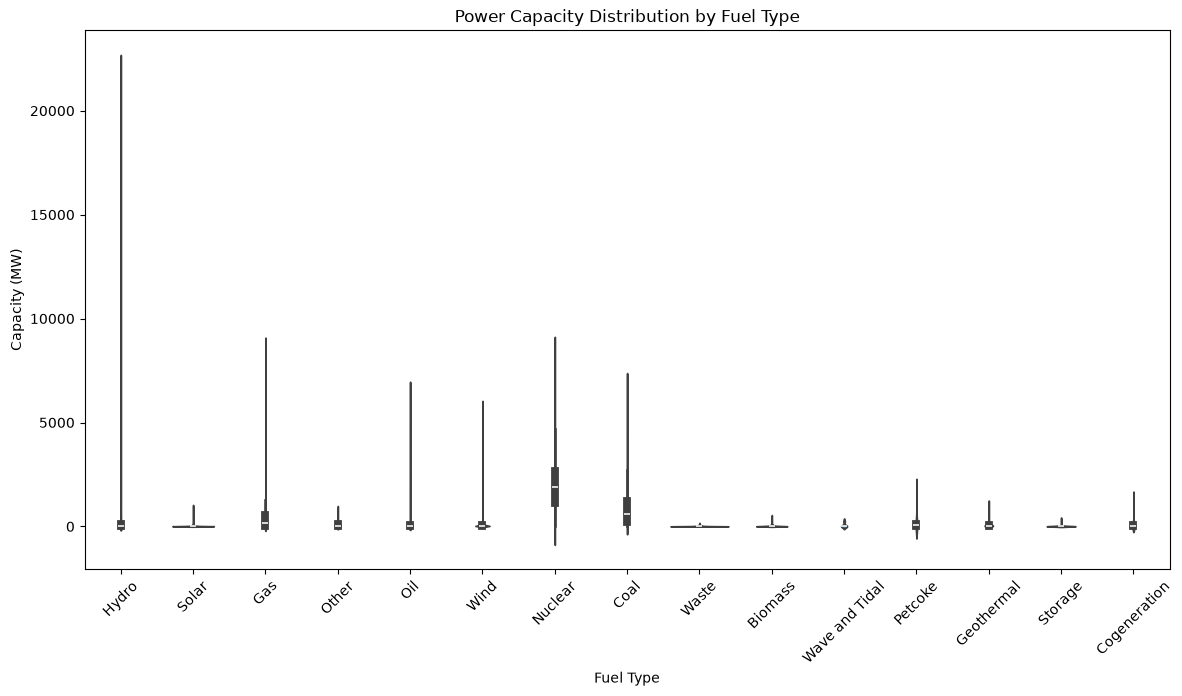

In [19]:
# Seaborn analysis
# Number of Power Plants by Fuel Type

# Count the number of power plants for each fuel type.
fuel_counts = df['primary_fuel'].value_counts()

# Create a figure with a specified size.
plt.figure(figsize=(10, 6))

# Create a horizontal bar chart showing the number of power plants for each fuel type.
sns.barplot(
    x=fuel_counts.values,
    y=fuel_counts.index,
    palette='viridis'
)

# Add a title and axis labels.
plt.title('Number of Power Plants by Fuel Type')
plt.xlabel('Number of Plants')
plt.ylabel('Fuel Type')

# Display the chart.
plt.show()

# Average Capacity by Fuel Type

# Calculate the average generating capacity (MW) for each fuel type.
capacity_stats = (
    df.groupby('primary_fuel')['capacity_mw']
      .mean()
      .sort_values(ascending=False)
)

# Create a new figure.
plt.figure(figsize=(12, 6))

# Create a bar chart showing average capacity by fuel type.
sns.barplot(
    x=capacity_stats.index,
    y=capacity_stats.values,
    palette='rocket'
)

# Rotate x-axis labels to improve readability.
plt.xticks(rotation=45)

# Add a title and axis labels.
plt.title('Average Capacity by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Mean Capacity (MW)')

# Display the chart.
plt.show()

# Capacity Distribution by Fuel Type

# Create a figure.
plt.figure(figsize=(14, 7))

# Create a boxplot showing the distribution of capacity for each fuel type.
# Boxplots show:
# - Median
# - Quartiles
# - Outliers
sns.boxplot(
    data=df,
    x='primary_fuel',
    y='capacity_mw'
)

# Rotate labels for readability.
plt.xticks(rotation=45)

# Add chart title and labels.
plt.title('Capacity Distribution by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Capacity (MW)')

# Display the chart.
plt.show()

# Log-Scaled Capacity Distribution

# Create another boxplot using a logarithmic scale. This is useful when capacities vary widely.
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x='primary_fuel',
    y='capacity_mw'
)

# Apply a logarithmic scale to the y-axis.
plt.yscale('log')

# Rotate x-axis labels.
plt.xticks(rotation=45)

# Add title and labels.
plt.title('Log-Scaled Capacity by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Capacity (MW) - Log Scale')

# Display the chart.
plt.show()

# Fuel Type Percentage Share

# Calculate the percentage share of each fuel type.
fuel_percentages = (
    df['primary_fuel']
      .value_counts(normalize=True)
      .mul(100)
)

# Identify fuel types that account for less than 1%.
small_categories = fuel_percentages[fuel_percentages < 1]

# Keep only fuel types that account for 1% or more.
fuel_percentages = fuel_percentages[fuel_percentages >= 1]

# Add a new "Other" category containing the combined percentage
# of all fuel types that were below 1%.
fuel_percentages['Other'] = small_categories.sum()

# Create a figure.
plt.figure(figsize=(10, 8))

# Create a pie chart showing the proportion of each fuel type.
plt.pie(
    fuel_percentages.values,
    labels=fuel_percentages.index,
    autopct='%1.1f%%',
    startangle=90
)

# Add a title.
plt.title('Fuel Type Share of Global Power Plants')

# Ensure the pie chart is displayed as a circle.
plt.axis('equal')

# Display the chart.
plt.show()

# Add a title.
plt.title('Fuel Type Share of Global Power Plants')

# Display the chart.
plt.show()

# Heatmap: Fuel Types Across Countries

# Create a contingency table showing the number of plants for each country and fuel type.
country_fuel = pd.crosstab(
    df['country_long'],
    df['primary_fuel']
)

# Select the 20 countries with the largest number of plants.
top_countries = (
    country_fuel.sum(axis=1)
    .sort_values(ascending=False)
    .head(20)
)

# Keep only the top 20 countries for the heatmap.
heatmap_data = country_fuel.loc[top_countries.index]

# Create the figure.
plt.figure(figsize=(14, 10))

# Create a heatmap. Darker colours indicate a larger number of power plants.
sns.heatmap(
    heatmap_data,
    cmap='YlGnBu'
)

# Add a title.
plt.title('Fuel Types Across Top 20 Countries')

# Display the chart.
plt.show()

# Top 10 Countries by Number of Power Plants

# Determine the ten countries with the highest number of power plants.
top_10 = (
    df['country_long']
    .value_counts()
    .head(10)
)

# Create a figure.
plt.figure(figsize=(12, 6))

# Create a horizontal bar chart.
sns.barplot(
    x=top_10.values,
    y=top_10.index,
    palette='mako'
)

# Add chart title and labels.
plt.title('Top 10 Countries by Number of Power Plants')
plt.xlabel('Plant Count')
plt.ylabel('Country')

# Display the chart.
plt.show()

# ANOVA Results Visualisation

# Create a violin plot to visualise the distribution of power plant capacities for each fuel type.
#
# Violin plots combine:
# - A boxplot
# - A density plot
#
# They provide a detailed view of the shape of the data.
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=df,
    x='primary_fuel',
    y='capacity_mw'
)

# Rotate x-axis labels for readability.
plt.xticks(rotation=45)

# Add chart title and labels.
plt.title('Power Capacity Distribution by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Capacity (MW)')

# Display the chart.
plt.show()

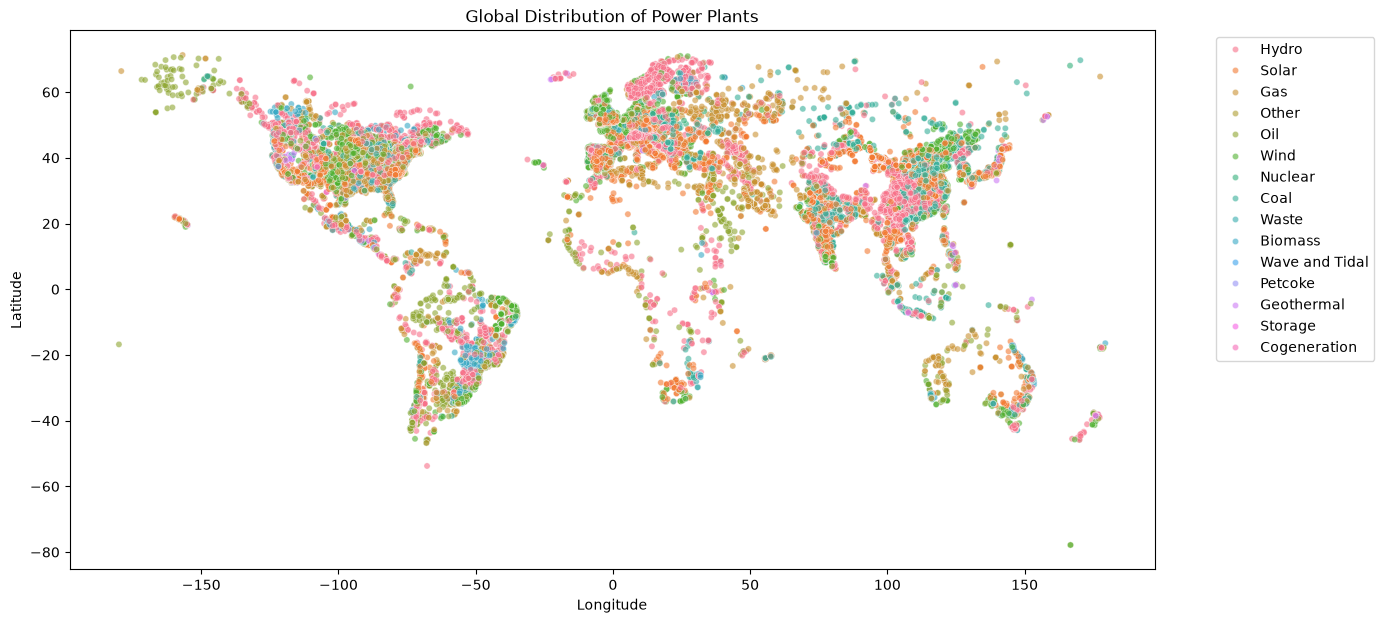

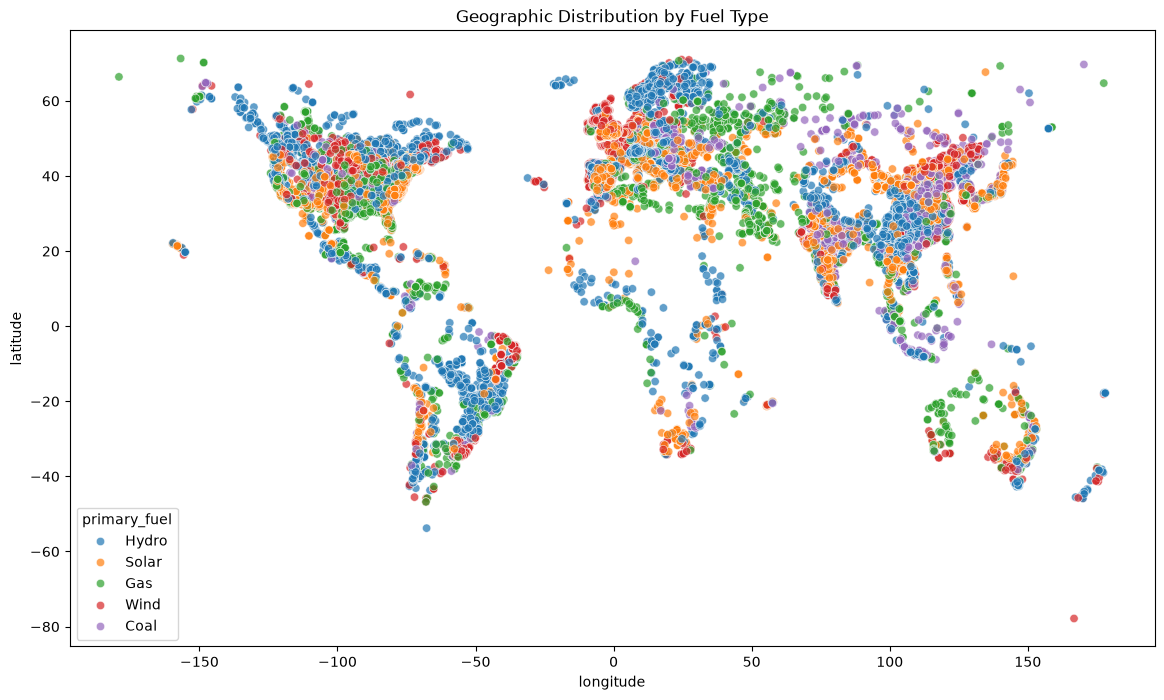

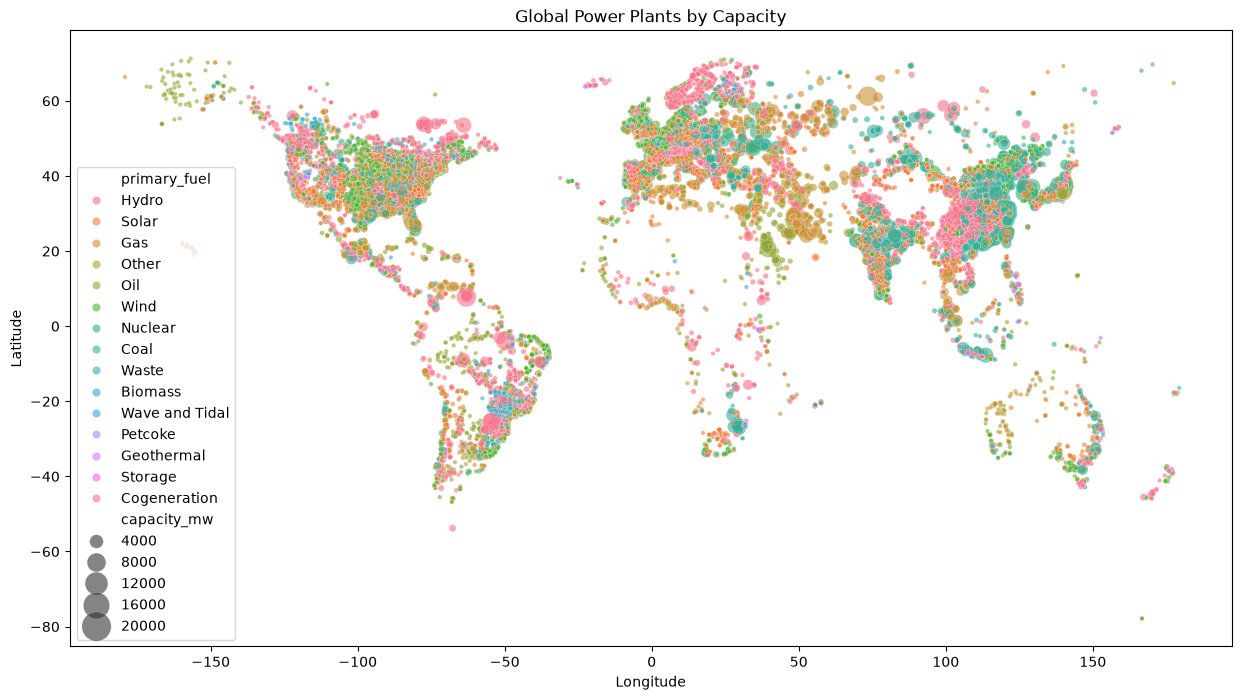

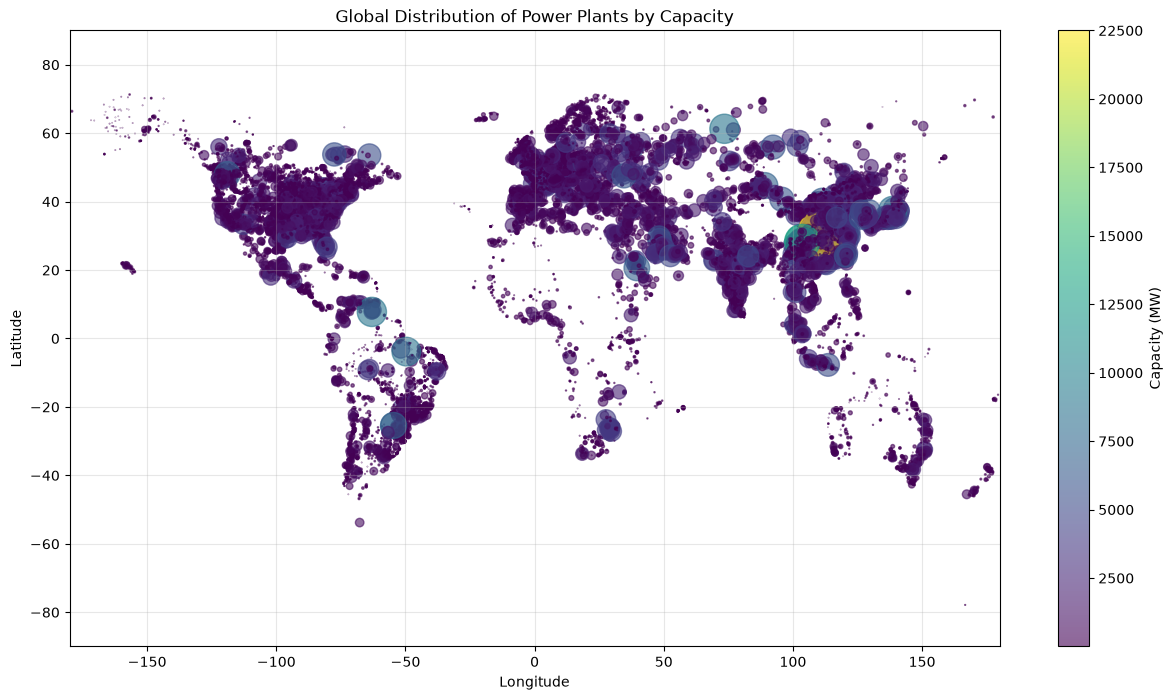

In [13]:
# Geographical distribution of power plants

# Remove rows with missing coordinates
geo_df = df[['latitude', 'longitude', 'primary_fuel']].dropna()

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=geo_df,
    x='longitude',
    y='latitude',
    hue='primary_fuel',
    alpha=0.6,
    s=20
)

plt.title('Global Distribution of Power Plants')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()

# Geographic distribution by fuel type
top_fuels = ['Solar', 'Hydro', 'Wind', 'Gas', 'Coal']

filtered_df = geo_df[
    geo_df['primary_fuel'].isin(top_fuels)
]

plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=filtered_df,
    x='longitude',
    y='latitude',
    hue='primary_fuel',
    alpha=0.7
)

plt.title('Geographic Distribution by Fuel Type')
plt.show()

# Bubble map using capacity

plt.figure(figsize=(15, 8))

sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    size='capacity_mw',
    hue='primary_fuel',
    alpha=0.6,
    sizes=(10, 500)
)

plt.title('Global Power Plants by Capacity')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

# Capacity by geographic location
# Create GeoDataFrame from latitude and longitude
plt.figure(figsize=(15, 8))

scatter = plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['capacity_mw'],
    s=df['capacity_mw'] / 20,
    cmap='viridis',
    alpha=0.6
)

plt.colorbar(scatter, label='Capacity (MW)')

plt.title('Global Distribution of Power Plants by Capacity')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# World coordinate boundaries
plt.xlim(-180, 180)
plt.ylim(-90, 90)

plt.grid(alpha=0.3)

plt.show()

In [20]:
# Matrix operations in real-world context

# Create a pivot table that groups the data by country and fuel type.

# Rows (index)- Each row represents a country.

# Columns:
#   - Each column represents a fuel type.
# Values:
#   - The average power plant capacity (capacity_mw) for that fuel type within each country.
#
# aggfunc='mean': Calculates the mean capacity when multiple plants exist for the same country and fuel type.
#
# fill_value=0:
#   - Replaces missing combinations with 0. For example, if a country has no solar plants, the solar value for that country will be 0.
capacity_matrix = pd.pivot_table(
    df,
    values='capacity_mw',
    index='country_long',
    columns='primary_fuel',
    aggfunc='mean',
    fill_value=0
)

# Convert the Pandas DataFrame into a NumPy array. This allows matrix operations to be performed using NumPy.
capacity_np = capacity_matrix.to_numpy()

# Perform matrix multiplication.
# capacity_np.T:
#   - Transposes the matrix so that fuel types become rows.
# @: Matrix multiplication operator.
#
# The resulting matrix measures relationships between fuel types based on their average capacities across countries.
#
# Diagonal values:
#   - Represent the relationship of each fuel type with itself.
#
# Off-diagonal values:
#   - Represent the degree of association between pairs of fuel types.
#   - Larger values indicate that the fuel types tend to have
#     similar capacity patterns across countries.
capacity_relationship = capacity_np.T @ capacity_np

# Display the resulting fuel-type relationship matrix.
print("Fuel Type Capacity Relationship Matrix:")
print(capacity_relationship)

Fuel Type Capacity Relationship Matrix:
[[1.45582397e+05 7.77363794e+05 4.03544598e+03 4.52109737e+05
  1.50443922e+04 2.38184109e+05 1.84416323e+06 3.64529182e+05
  1.46375162e+04 8.28787545e+03 2.73684475e+04 4.65297645e+02
  8.69495515e+03 1.55335744e+04 6.68845983e+04]
 [7.77363794e+05 6.23897172e+07 6.86729921e+05 2.38810532e+07
  6.99947854e+05 1.09356863e+07 4.47803477e+07 1.64409603e+07
  5.72342215e+05 2.08797067e+05 1.33162891e+06 5.12907963e+04
  1.63980097e+05 6.60560406e+05 1.86946743e+06]
 [4.03544598e+03 6.86729921e+05 1.85348140e+05 2.42791833e+05
  1.83373140e+03 2.51187659e+04 5.33782016e+05 1.58375794e+04
  1.09639853e+03 6.57964492e+03 3.53846640e+03 1.26619114e+04
  3.01456182e+03 2.34345306e+03 1.55852721e+04]
 [4.52109737e+05 2.38810532e+07 2.42791833e+05 3.76077667e+07
  4.59156966e+05 1.01782084e+07 2.79693108e+07 1.72643161e+07
  2.67142604e+05 8.16944401e+04 1.31035552e+06 1.80908532e+04
  1.69159313e+05 3.84626407e+05 1.54267354e+06]
 [1.50443922e+04 6.99947

Eigenvalues and eigenvectors help find hidden patterns in the matrix. Eigenvalues show how important each pattern is, while eigenvectors show which fuel types contribute to those patterns. In this context, they can be used to identify fuel types that have similar power generation capacity trends across different countries.

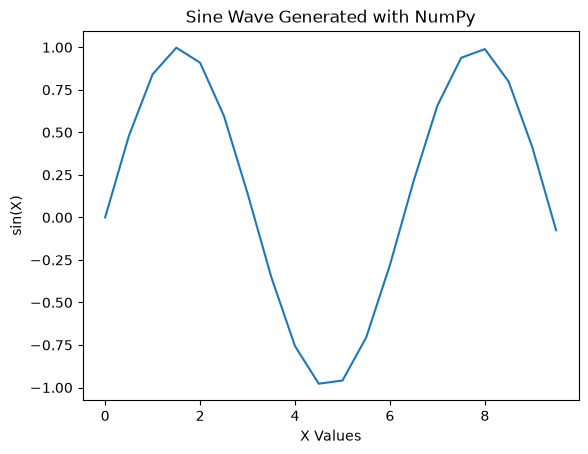

   capacity_mw Size_Category
0         33.0         Small
1         10.0         Small
2         10.0         Small
3         66.0         Small
4        100.0         Small


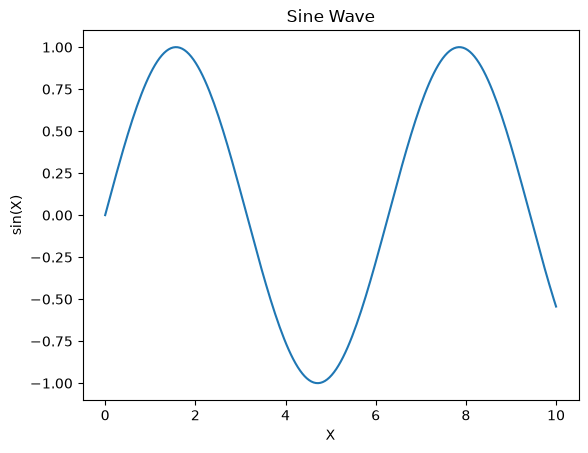

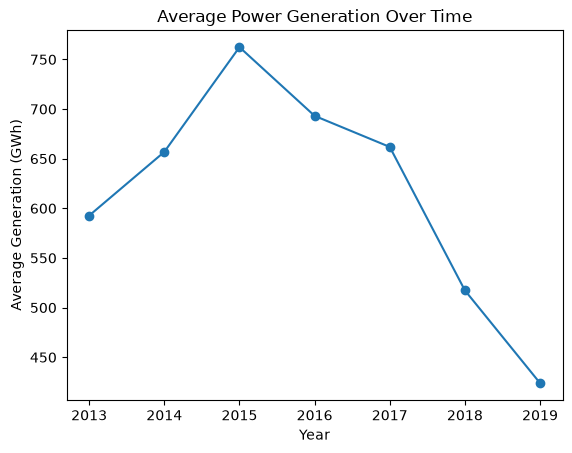

In [23]:
# Integrating NumPy with Pandas and Matplotlib

# Use Numpy to generate data then visualise with Matplotlib

# Generate values for the x-axis.
x = np.arange(0, 10, 0.5)

# Generate y-values using NumPy.
# This creates a sine wave.
y = np.sin(x)

# Create the plot.
plt.plot(x, y)

# Add labels and title.
plt.title('Sine Wave Generated with NumPy')
plt.xlabel('X Values')
plt.ylabel('sin(X)')

# Display the graph.
plt.show()

# NumPy's where() function can efficiently create new columns based on conditions.
# Classify power plants by capacity.
 
df['Size_Category'] = np.where(
df['capacity_mw'] > np.mean(df['capacity_mw']),
'Large',
'Small'
)
 
# Display the new column.
print(df[['capacity_mw', 'Size_Category']].head())

# NumPy can generate mathematical functions that are then visualised with Matplotlib. 
# Generate x values.
x = np.linspace(0, 10, 200)
 
# Generate y values using NumPy.
y = np.sin(x)
 
# Create a line graph.
plt.plot(x, y)
 
# Add labels and title.
plt.title("Sine Wave")
plt.xlabel("X")
plt.ylabel("sin(X)")
 
# Display the graph.
plt.show()
# How NumPy helps:
# np.linspace() generates evenly spaced values.
# np.sin() calculates the sine function for the entire array.

# Using NumPy to Improve a Power Plant Visualisation
# Calculate yearly average generation using NumPy and visualise the trend using Matplotlib.

# Select yearly generation columns.
generation_cols = [
'generation_gwh_2013',
'generation_gwh_2014',
'generation_gwh_2015',
'generation_gwh_2016',
'generation_gwh_2017',
'generation_gwh_2018',
'generation_gwh_2019'
]
 
# Calculate yearly averages using NumPy.
yearly_means = [
np.nanmean(df[col])
for col in generation_cols
]
 
# Create an array of years.
years = np.arange(2013, 2020)
 
# Create the plot.
plt.plot(
years,
yearly_means,
marker='o'
)
 
# Add labels and title.
plt.title('Average Power Generation Over Time')
plt.xlabel('Year')
plt.ylabel('Average Generation (GWh)')
 
# Display the graph.
plt.show()

# How NumPy helps
# np.nanmean() calculates averages while ignoring missing values.
# np.arange() creates the sequence of years used on the x-axis.